In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows with MKL.*",
    category=UserWarning
)

In [2]:
X, y_true = make_blobs(
    n_samples=500,
    centers=3,
    cluster_std=0.60,
    random_state=42
)

In [3]:
df=pd.DataFrame(X, columns=['Feature 1','Feature 2'])
print(df)

     Feature 1  Feature 2
0    -6.190063  -7.302015
1     3.021747   1.940593
2     5.953761   1.488191
3    -2.744463   8.136177
4     5.360607   1.728324
..         ...        ...
495  -6.040014  -6.325329
496  -2.555459   9.218977
497   4.438408   2.974583
498  -7.193261  -6.250704
499   4.951487   2.892813

[500 rows x 2 columns]


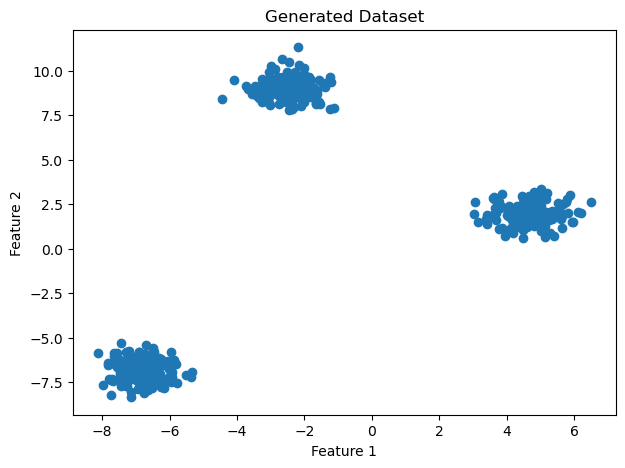

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 1])

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Generated Dataset")

plt.show()

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [5]:
inertia=[]
K_range=range(1, 11)

In [6]:
for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [7]:
inertia

[1000.0000000000001,
 297.8954141051722,
 11.57548472310498,
 9.748920654325133,
 8.25717527244628,
 6.917577320416799,
 6.260760667208617,
 5.679769508143491,
 5.01820499476035,
 4.428456966876499]

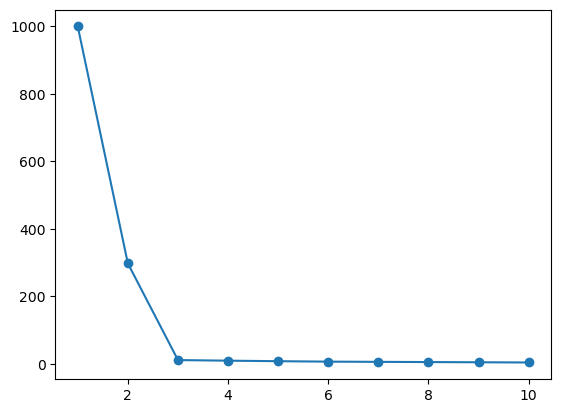

In [9]:
plt.plot(K_range,inertia, marker='o')

In [10]:
kmeans_final=KMeans(n_clusters=3,random_state=42)

In [13]:
cluster_labels = kmeans_final.fit_predict(X_scaled)

In [15]:
df['cluster']=cluster_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

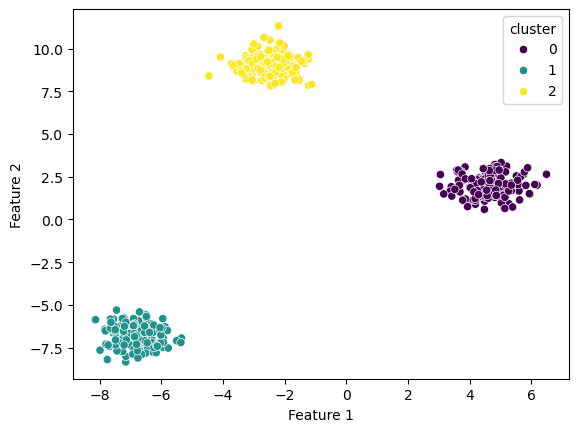

In [16]:
sns.scatterplot(x=df['Feature 1'],
                y=df['Feature 2'],
                hue = df['cluster'],
                palette='viridis')